# 🔓 Solutions: Practical Assignment

> **Try first, peek second.** You learn far more by struggling with a problem for ten minutes than by reading its answer for ten seconds. Use these solutions to *compare* your approach, not to replace it. There is often more than one correct way.


In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 🧩 Step 9.1: Load the dataset &nbsp; ⭐

**Load** `housing.csv` into a DataFrame called `df` (use `load("housing.csv")`). Then inspect it and record:

* `n_rows`: number of rows,
* `n_cols`: number of columns,
* `n_missing`: the total number of missing values in the whole table.

Also *look* at the data (`df.head()`, `df.describe()`, `df.dtypes`). Real projects begin with **looking**, not modelling. Does anything look odd: impossible values, weird ranges?

In [2]:
df = load("housing.csv")
n_rows, n_cols = df.shape
n_missing = int(df.isna().sum().sum())

print(f"{n_rows} rows, {n_cols} columns, {n_missing} missing values")
display(df.head())
display(df.describe().T.round(1))

900 rows, 8 columns, 0 missing values


,area_sqm,bedrooms,bathrooms,age_years,distance_to_center_km,has_garden,neighborhood_quality,price_k
0,127.6,2,1,39,4.8,1,3,504.0
1,99.1,1,1,23,20.9,1,3,367.8
2,103.5,2,1,7,1.1,1,4,515.9
3,40.0,1,1,54,8.2,1,5,218.7
4,192.0,5,2,9,39.0,0,4,644.3


,count,mean,std,min,25%,50%,75%,max
area_sqm,900.0,118.9,39.6,40.0,91.7,118.6,145.2,242.3
bedrooms,900.0,2.6,1.1,1.0,2.0,3.0,3.0,6.0
bathrooms,900.0,1.7,0.7,1.0,1.0,2.0,2.0,4.0
age_years,900.0,30.2,17.6,0.0,14.8,31.0,45.0,60.0
distance_to_center_km,900.0,7.7,7.6,0.5,2.3,5.4,10.7,40.0
has_garden,900.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
neighborhood_quality,900.0,3.1,1.1,1.0,2.0,3.0,4.0,5.0
price_k,900.0,478.6,173.5,50.0,353.1,472.6,583.4,1143.3


In [3]:
# ✔ Self-check
check("df is the housing table", lambda: list(df.columns)[-1] == "price_k")
check("900 rows", lambda: n_rows == 900)
check("8 columns", lambda: n_cols == 8)
check("no missing values", lambda: n_missing == 0)

✅ PASSED   df is the housing table
✅ PASSED   900 rows
✅ PASSED   8 columns
✅ PASSED   no missing values


True

**🧑‍🏫 Walkthrough.** `shape` tells us the size; `isna().sum().sum()` totals missing cells (none here (real data is rarely so tidy; the Capstone has missing values to deal with). From `describe()` we notice: areas from ~40 to 300 m², prices from ~$100k to well over $1M, and a minimum of 1 bedroom) all plausible, no impossible values. **Always sanity-check ranges before trusting a dataset.**

### 🧩 Step 9.2: Separate features and target &nbsp; ⭐

Create the feature table `X` (all columns **except** `price_k`) and the target `y` (the `price_k` column).

In [4]:
X = df.drop(columns="price_k")
y = df["price_k"]
print("features:", list(X.columns))
print("target  :", y.name)

features: ['area_sqm', 'bedrooms', 'bathrooms', 'age_years', 'distance_to_center_km', 'has_garden', 'neighborhood_quality']
target  : price_k


In [5]:
# ✔ Self-check
check("X has 7 feature columns", lambda: X.shape == (900, 7))
check("the target is NOT in X (no leakage!)", lambda: "price_k" not in X.columns)
check("y is the price column", lambda: y.name == "price_k" and len(y) == 900)

✅ PASSED   X has 7 feature columns
✅ PASSED   the target is NOT in X (no leakage!)
✅ PASSED   y is the price column


True

**🧑‍🏫 Walkthrough.** Seven features (inputs) and one target (what we predict). The check "target not in X" guards against the most embarrassing mistake in ML: giving the model the answer.

### 🧩 Step 9.3: Split the dataset &nbsp; ⭐⭐

Split into **training (80%)** and **test (20%)** sets using `train_test_split` with **`random_state=42`**. Name the pieces `X_train, X_test, y_train, y_test`.

*Reminder from Lesson 4: the test set is a sealed envelope. You will open it **once**, in Step 6.*

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"train: {X_train.shape},  test: {X_test.shape}")

train: (720, 7),  test: (180, 7)


In [7]:
# ✔ Self-check
check("720 training rows", lambda: len(X_train) == 720 and len(y_train) == 720)
check("180 test rows", lambda: len(X_test) == 180 and len(y_test) == 180)
check("same split as test_size=0.2, random_state=42", lambda: list(X_test.index) == list(train_test_split(X, y, test_size=0.2, random_state=42)[1].index))
check("no overlap between train and test", lambda: not set(X_train.index) & set(X_test.index))

✅ PASSED   720 training rows
✅ PASSED   180 test rows
✅ PASSED   same split as test_size=0.2, random_state=42
✅ PASSED   no overlap between train and test


True

**🧑‍🏫 Walkthrough.** Splitting *before* looking at model results (and before any scaling or tuning) is what keeps the test set honest. `random_state=42` makes the split reproducible, so your results match your classmates', and your own tomorrow.

### 🧩 Step 9.4: Train a regression model &nbsp; ⭐⭐

1. Create and **fit** a `LinearRegression` on the **training data only** → `model`.
2. Also fit a **baseline** `DummyRegressor(strategy="mean")` on the training data → `baseline`.
3. Build `coefs`: a pandas Series of the model's coefficients, indexed by feature name.

In [8]:
model = LinearRegression().fit(X_train, y_train)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
coefs = pd.Series(model.coef_, index=X_train.columns)

print(f"baseline always predicts {baseline.constant_[0][0]:.0f}  ($1000s)")
print(f"model intercept = {model.intercept_:.1f}")
print(coefs.round(2).sort_values().to_string())

baseline always predicts 474  ($1000s)
model intercept = -68.0
distance_to_center_km    -4.53
age_years                -1.71
bedrooms                  2.15
area_sqm                  3.79
bathrooms                10.27
has_garden               22.85
neighborhood_quality     48.15


In [9]:
# ✔ Self-check
check("model is a fitted LinearRegression with 7 coefficients", lambda: isinstance(model, LinearRegression) and len(model.coef_) == 7)
check("baseline is a fitted DummyRegressor", lambda: isinstance(baseline, DummyRegressor) and hasattr(baseline, "constant_"))
check("the model was trained on the training set only (compare intercepts)", lambda: abs(model.intercept_ - LinearRegression().fit(X_train, y_train).intercept_) < 1e-9)
check("coefs is a labelled Series; age lowers the price", lambda: isinstance(coefs, pd.Series) and coefs["age_years"] < 0)

✅ PASSED   model is a fitted LinearRegression with 7 coefficients
✅ PASSED   baseline is a fitted DummyRegressor
✅ PASSED   the model was trained on the training set only (compare intercepts)
✅ PASSED   coefs is a labelled Series; age lowers the price


True

**🧑‍🏫 Walkthrough.** The baseline ("always guess the average price") is our yardstick. The learned coefficients are the *model*: for instance, each extra year of age lowers the predicted price by about $1.7k, a garden adds about $23k, and each additional step of neighbourhood quality adds about $48k. *(Careful: these describe the model, not necessarily causal effects.)*

### 🧩 Step 9.5: Generate predictions &nbsp; ⭐

Use the fitted `model` to predict prices for **both** the training and the test features:

* `y_pred_train`: predictions for `X_train`
* `y_pred_test`: predictions for `X_test`

Then also compute `y_base_test`, the **baseline's** predictions for `X_test`.

In [10]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
y_base_test = baseline.predict(X_test)

preview = pd.DataFrame({"actual": y_test.values[:5], "predicted": y_pred_test[:5].round(1)})
preview["error"] = (preview["actual"] - preview["predicted"]).round(1)
print(preview.to_string(index=False))

 actual  predicted  error
  606.1      609.0   -2.9
  477.2      504.7  -27.5
  929.8      971.7  -41.9
  733.7      752.9  -19.2
  435.3      467.9  -32.6


In [11]:
# ✔ Self-check
check("one prediction per training row", lambda: len(y_pred_train) == 720)
check("one prediction per test row", lambda: len(y_pred_test) == 180)
check("test predictions come from the model", lambda: np.allclose(y_pred_test, model.predict(X_test)))
check("baseline predicts one constant value for everyone", lambda: np.allclose(y_base_test, y_base_test[0]) and len(y_base_test) == 180)

✅ PASSED   one prediction per training row
✅ PASSED   one prediction per test row
✅ PASSED   test predictions come from the model
✅ PASSED   baseline predicts one constant value for everyone


True

**🧑‍🏫 Walkthrough.** This is **inference**: the model has never seen the test houses, yet it produces a price for each. We also predict on the training data: not to evaluate (that would be dishonest) but to *compare* train vs test performance in the next step, which is how we detect overfitting.

### 🧩 Step 9.6: Evaluate the model &nbsp; ⭐⭐⭐

Compute **MAE, RMSE and R²** for the model on both the **training** and the **test** sets, and store them in a dictionary:

```python
metrics = {"train": {"MAE": ..., "RMSE": ..., "R2": ...},
           "test":  {"MAE": ..., "RMSE": ..., "R2": ...}}
```

Also compute the **baseline's test RMSE** (`baseline_rmse`) and the **percentage improvement** of the model's test RMSE over it (`improvement_pct`, as in Lesson 6).

Finally, draw a **residual plot** for the test set (predicted on the x-axis, `actual − predicted` on the y-axis, with a horizontal line at 0). *A plot can't be auto-checked, but your Step 7 explanation will need it.*

,train,test
MAE,23.359,25.580
RMSE,31.541,33.023
R2,0.968,0.960


baseline test RMSE = 167.2   →   model test RMSE = 33.0   (80% better)


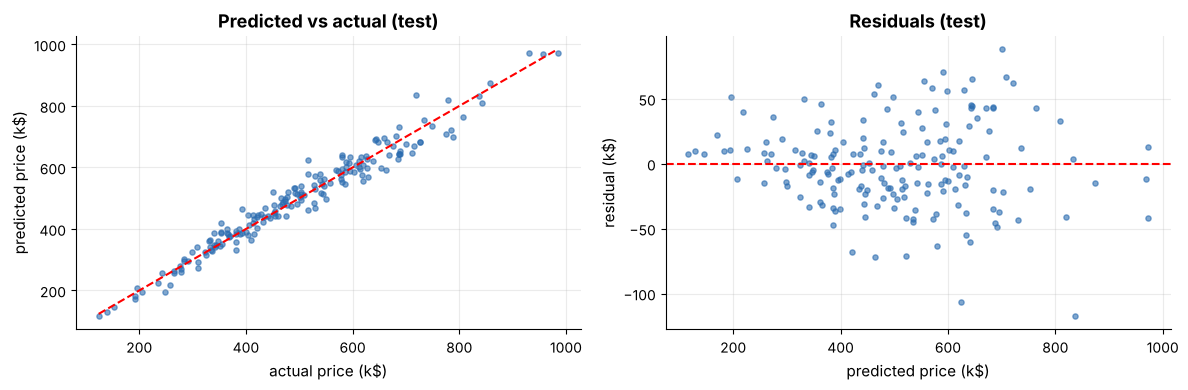

In [12]:
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

metrics = {"train": evaluate(y_train, y_pred_train), "test": evaluate(y_test, y_pred_test)}
baseline_rmse = float(np.sqrt(mean_squared_error(y_test, y_base_test)))
improvement_pct = 100 * (baseline_rmse - metrics["test"]["RMSE"]) / baseline_rmse

display(pd.DataFrame(metrics).round(3))
print(f"baseline test RMSE = {baseline_rmse:.1f}   →   model test RMSE = {metrics['test']['RMSE']:.1f}   ({improvement_pct:.0f}% better)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, y_pred_test, s=14, alpha=0.6); lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("actual price (k$)"); axes[0].set_ylabel("predicted price (k$)"); axes[0].set_title("Predicted vs actual (test)")
axes[1].scatter(y_pred_test, y_test - y_pred_test, s=14, alpha=0.6); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("predicted price (k$)"); axes[1].set_ylabel("residual (k$)"); axes[1].set_title("Residuals (test)")
plt.tight_layout(); plt.show()

In [13]:
# ✔ Self-check
check("test RMSE is correct", lambda: abs(metrics["test"]["RMSE"] - np.sqrt(mean_squared_error(y_test, y_pred_test))) < 1e-9)
check("test MAE is correct", lambda: abs(metrics["test"]["MAE"] - mean_absolute_error(y_test, y_pred_test)) < 1e-9)
check("train R² is correct", lambda: abs(metrics["train"]["R2"] - r2_score(y_train, y_pred_train)) < 1e-9)
check("model is strong (test R² > 0.95)", lambda: metrics["test"]["R2"] > 0.95)
check("baseline RMSE is correct", lambda: abs(baseline_rmse - np.sqrt(mean_squared_error(y_test, y_base_test))) < 1e-9)
check("improvement over baseline is > 75%", lambda: improvement_pct > 75)

✅ PASSED   test RMSE is correct
✅ PASSED   test MAE is correct
✅ PASSED   train R² is correct
✅ PASSED   model is strong (test R² > 0.95)
✅ PASSED   baseline RMSE is correct
✅ PASSED   improvement over baseline is > 75%


True

**🧑‍🏫 Walkthrough.** **Reading the results:** train and test scores are close (no sign of overfitting), the test R² is about 0.96, a typical miss (MAE) is roughly $26k, and the RMSE is about $33k (an ~80% reduction versus guessing the average. (Training RMSE is a touch lower, $32k, which is perfectly normal.) The residual plot shows a **fan**: errors grow with price (heteroscedasticity), so expensive homes are predicted less precisely. *That* observation) not just the numbers: is what makes the explanation in Step 7 insightful.

### 🧩 Step 9.7: Explain the performance &nbsp; ⭐⭐⭐

Your manager isn't a data scientist. Write a short, **plain-English** explanation by filling in each field of the dictionary `explanation` (one or two sentences each, **at least 60 characters per field**, and **quote numbers from your results**).

**Writing guide: good explanations are:**
* **Quantitative**: "typically off by about $26k (≈ 5%)", not "pretty accurate".
* **Comparative**: always against the baseline.
* **Honest**: mention limits and what you *didn't* test.
* **Jargon-free**: if you must say "RMSE", translate it.

Fields: `task`, `performance`, `baseline`, `generalization`, `errors`, `drivers`, `limitations`.

In [14]:
t = metrics["test"]; tr = metrics["train"]
explanation = {
    "task": "The model estimates a home's sale price (in thousands of dollars) from seven facts about it: area, bedrooms, bathrooms, age, distance to the centre, whether it has a garden, and neighbourhood quality.",
    "performance": f"On 180 homes it had never seen, the model's estimate is typically off by about ${t['MAE']:.0f}k (the average miss); larger misses weigh more, giving an RMSE of ${t['RMSE']:.0f}k. With an R² of {t['R2']:.2f} it explains about {t['R2']*100:.0f}% of the variation in prices.",
    "baseline": f"Simply guessing the average price for every home gives a typical error of about ${baseline_rmse:.0f}k, so the model reduces the error by roughly {improvement_pct:.0f}%: it has genuinely learned something useful.",
    "generalization": f"Training and test scores are nearly identical (R² {tr['R2']:.3f} vs {t['R2']:.3f}; RMSE ${tr['RMSE']:.0f}k vs ${t['RMSE']:.0f}k), so there is no sign of overfitting: the model performs about as well on new homes as on the ones it learned from.",
    "errors": "The residual plot fans out: errors are small for cheaper homes and larger for expensive ones, so estimates for luxury properties are less reliable. The model is also not systematically too high or too low (residuals centre on zero).",
    "drivers": "Holding other features equal, higher neighbourhood quality, larger area, a garden and more bathrooms raise the predicted price, while greater age and a longer distance from the centre lower it. These describe patterns the model found, not proven causes.",
    "limitations": "The data comes from one market and one period, so it may not hold elsewhere or after the market shifts. The model is a straight-line (linear) one that cannot capture curved effects, its errors are uneven across price levels, and I evaluated on a single split rather than with cross-validation.",
}
for k, v in explanation.items():
    print(f"• {k.upper()}: {v}\n")

• TASK: The model estimates a home's sale price (in thousands of dollars) from seven facts about it: area, bedrooms, bathrooms, age, distance to the centre, whether it has a garden, and neighbourhood quality.

• PERFORMANCE: On 180 homes it had never seen, the model's estimate is typically off by about $26k (the average miss); larger misses weigh more, giving an RMSE of $33k. With an R² of 0.96 it explains about 96% of the variation in prices.

• BASELINE: Simply guessing the average price for every home gives a typical error of about $167k, so the model reduces the error by roughly 80%: it has genuinely learned something useful.

• GENERALIZATION: Training and test scores are nearly identical (R² 0.968 vs 0.960; RMSE $32k vs $33k), so there is no sign of overfitting: the model performs about as well on new homes as on the ones it learned from.

• ERRORS: The residual plot fans out: errors are small for cheaper homes and larger for expensive ones, so estimates for luxury properties are

In [15]:
# ✔ Self-check
fields = ["task", "performance", "baseline", "generalization", "errors", "drivers", "limitations"]
check("all seven fields exist", lambda: sorted(explanation) == sorted(fields))
for f in fields:
    check(f"'{f}' has at least 60 characters", lambda: len(explanation[f].strip()) >= 60)
check("you quoted at least five numbers in total", lambda: sum(ch.isdigit() for ch in " ".join(explanation.values())) >= 10)

✅ PASSED   all seven fields exist
✅ PASSED   'task' has at least 60 characters
✅ PASSED   'performance' has at least 60 characters
✅ PASSED   'baseline' has at least 60 characters
✅ PASSED   'generalization' has at least 60 characters
✅ PASSED   'errors' has at least 60 characters
✅ PASSED   'drivers' has at least 60 characters
✅ PASSED   'limitations' has at least 60 characters
✅ PASSED   you quoted at least five numbers in total


True

**🧑‍🏫 Walkthrough.** Notice what makes this explanation strong: each claim carries a **number**, the model is compared with the **baseline**, the train/test gap is discussed (**generalization**), the residual plot is *interpreted* rather than merely shown, and the limitations section is concrete. Weak versions say "the model is accurate" or "R² is high", which tells your manager nothing actionable.